# LINEBENCH — 01 Instance Inventory & Structural Analysis

This notebook explores the pre-declared instance subset defined in `configs/instances.yaml`:
1. Analyzes problem sizes, order strengths ($OS$), and graph structures.
2. Computes theoretical lower bounds $LB_1$ and $LB_2$.
3. Compares lower bounds against published optima / best-known values to measure bound tightness.
4. Displays structural breakdowns by stratum (Classical vs. Generated).

In [1]:
from pathlib import Path
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from linebench.instances.subset import load_subset_instance
from linebench.instances.measures import compute_instance_measures

# Set plotting style
sns.set_theme(style="whitegrid")

# Load frozen instances subset
with open("../configs/instances.yaml", "r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

print("Subset Metadata:", data["metadata"])

Subset Metadata: {'master_seed': 42, 'simulation_seed': 2026, 'total_benchmark_instances': 395, 'classical_instances_count': 206, 'generated_instances_count': 189, 'simulation_instances_count': 30}


In [2]:
# Compute structural measures across all benchmark instances
records = []
for entry in data["benchmark_instances"]:
    inst = load_subset_instance(entry)
    m = compute_instance_measures(inst)
    rec = m.to_dict()
    rec["stratum"] = entry["stratum"]
    rec["optimal_stations"] = entry["optimal_stations"]
    rec["best_known_stations"] = entry["best_known_stations"]
    rec["is_optimum_proven"] = entry["is_optimum_proven"]
    rec["cell"] = entry.get("cell")
    
    # Bound comparison
    ref = entry["optimal_stations"] or entry["best_known_stations"]
    if ref:
        rec["lb_gap"] = (ref - rec["lb"]) / ref
        rec["lb_exact_hit"] = (rec["lb"] == ref)
    else:
        rec["lb_gap"] = None
        rec["lb_exact_hit"] = None
        
    records.append(rec)

df = pd.DataFrame(records)
print(f"Computed measures for {len(df)} instances.")
df.head()

Computed measures for 395 instances.


,name,num_tasks,cycle_time,total_work,order_strength,num_precedence_pairs_direct,num_precedence_pairs_transitive,num_sources,num_sinks,avg_in_degree,...,lb1,lb2,lb,stratum,optimal_stations,best_known_stations,is_optimum_proven,cell,lb_gap,lb_exact_hit
0,scholl_arcus1_c3786,83,3786,75707,0.590949,113,2011,1,1,1.361446,...,20,5,20,classical,21.0,21.0,True,NaN,0.047619,False
1,scholl_arcus1_c3985,83,3985,75707,0.590949,113,2011,1,1,1.361446,...,19,5,19,classical,20.0,20.0,True,NaN,0.050000,False
2,scholl_arcus1_c4206,83,4206,75707,0.590949,113,2011,1,1,1.361446,...,18,4,18,classical,19.0,19.0,True,NaN,0.052632,False
3,scholl_arcus1_c4454,83,4454,75707,0.590949,113,2011,1,1,1.361446,...,17,4,17,classical,18.0,18.0,True,NaN,0.055556,False
4,scholl_arcus1_c4732,83,4732,75707,0.590949,113,2011,1,1,1.361446,...,16,3,16,classical,17.0,17.0,True,NaN,0.058824,False


In [3]:
# Stratum Summary Statistics
summary = df.groupby("stratum").agg(
    instances=("name", "count"),
    mean_tasks=("num_tasks", "mean"),
    min_tasks=("num_tasks", "min"),
    max_tasks=("num_tasks", "max"),
    mean_OS=("order_strength", "mean"),
    mean_tightness=("tightness_ratio", "mean"),
    lb_exact_hit_rate=("lb_exact_hit", "mean"),
    mean_lb_gap=("lb_gap", "mean"),
)
summary

,instances,mean_tasks,min_tasks,max_tasks,mean_OS,mean_tightness,lb_exact_hit_rate,mean_lb_gap
stratum,,,,,,,,
classical,206,67.281553,7,297,0.547350,1.605300,0.432039,0.042882
generated,189,56.666667,20,100,0.458924,2.063721,0.793548,0.017338


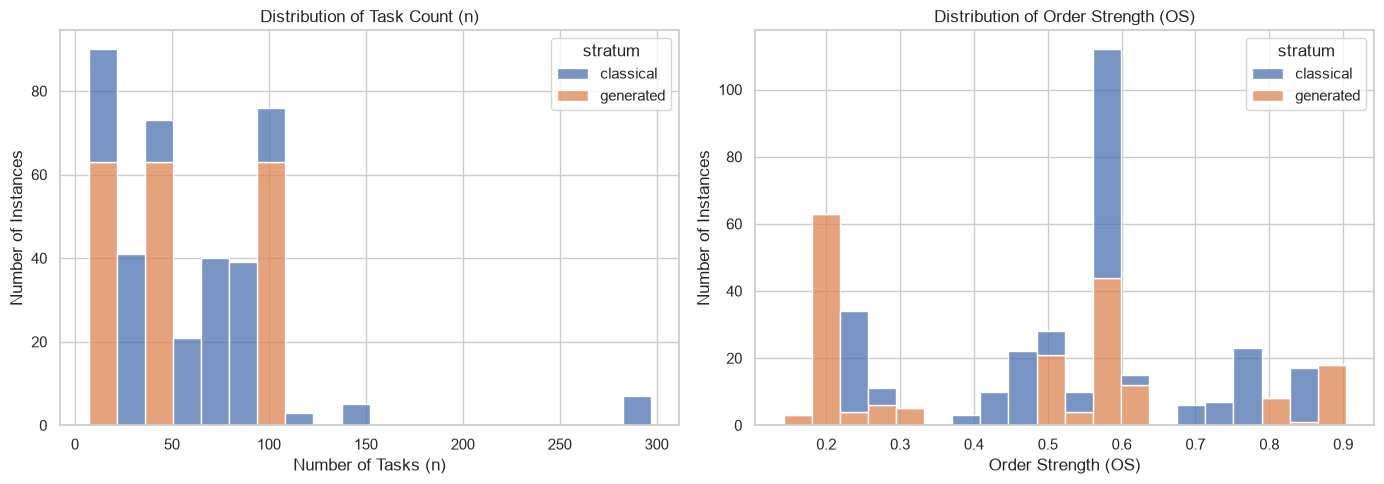

In [4]:
# Figure: Distribution of Problem Size and Order Strength
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="num_tasks", hue="stratum", multiple="stack", bins=20, ax=axes[0])
axes[0].set_title("Distribution of Task Count (n)")
axes[0].set_xlabel("Number of Tasks (n)")
axes[0].set_ylabel("Number of Instances")

sns.histplot(data=df, x="order_strength", hue="stratum", multiple="stack", bins=20, ax=axes[1])
axes[1].set_title("Distribution of Order Strength (OS)")
axes[1].set_xlabel("Order Strength (OS)")
axes[1].set_ylabel("Number of Instances")

plt.tight_layout()
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_132\1914612592.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df.dropna(subset=["lb_gap"]), x="stratum", y="lb_gap", palette="Set2")


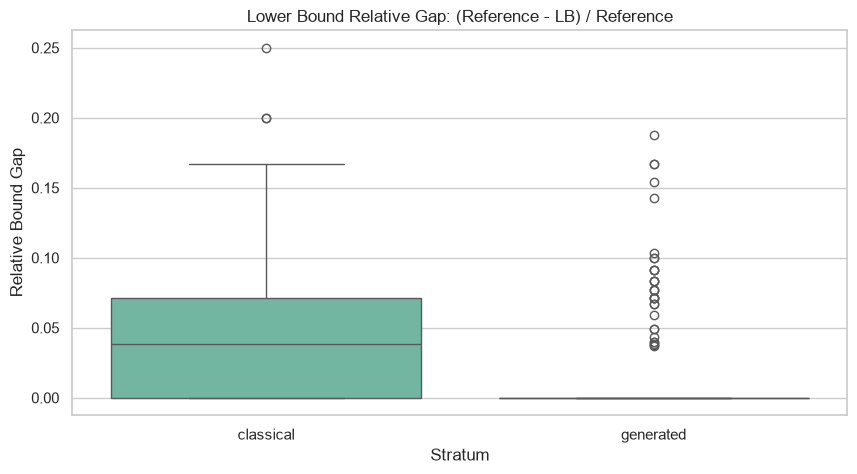

In [5]:
# Figure: Lower Bound Tightness Comparison
plt.figure(figsize=(10, 5))
sns.boxplot(data=df.dropna(subset=["lb_gap"]), x="stratum", y="lb_gap", palette="Set2")
plt.title("Lower Bound Relative Gap: (Reference - LB) / Reference")
plt.ylabel("Relative Bound Gap")
plt.xlabel("Stratum")
plt.show()